# Thí nghiệm 4: Khả năng cải thiện GA trên các bài TSP lớn hơn

**Đề tài 6, nhóm 9 — UEH.** Trưởng nhóm Trương Thành Đạt phụ trách GA; ba thành viên còn lại phụ trách EHO. Notebook này chỉ thực nghiệm Genetic Algorithm (thuật toán di truyền). EHO chưa được triển khai; GUI GA đã có nhưng không tham gia đo thời gian ở đây.

**Cách chạy:** từ root dự án cài `python -m pip install -r requirements.txt`, mở Jupyter hoặc VS Code, chọn interpreter `.venv`, rồi **Restart Kernel & Run All**. Có thể mở từ root hoặc thư mục `Experiment/`. Nếu import lỗi, kiểm tra kernel và cài package bằng interpreter đó; không chỉnh `sys.path`.

Giữ `MODE = 'QUICK'` cho lần đầu. Chế độ này sử dụng năm seed `[11, 23, 37, 53, 71]`; seed là số khởi tạo bộ sinh ngẫu nhiên, giúp chạy lại cùng một phép thử. Đổi sang `FULL` rồi khởi động lại kernel để dùng 25 seed `[101, ..., 125]`. Đây là hai tập khác nhau, không gộp chúng thành một mẫu. Mọi lần chạy có số thế hệ hữu hạn và các nhóm so sánh cùng số phép tính còn có giới hạn evaluations. Notebook không tự chạy lại để tìm một kết quả mong muốn và không xuất file kết quả vào repository.

Chúng tôi đã đọc ba notebook tham chiếu từ Git history `5d81c76` của source được đưa vào dự án, có nguồn [repository đàn anh](https://github.com/ThienNguyen3001/Travelling-Salesman-Genetic-AI-Final). Bản mới giữ thứ tự giới thiệu trường hợp, chạy, vẽ và nhận xét; toàn bộ code gọi package GA hiện tại. Các kết luận, ảnh và số liệu cũ không được dùng lại làm kết quả mới. Không sử dụng các toán tử Single-Point, Two-Point hoặc Uniform Crossover của bản cũ.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
from collections import Counter
from math import fsum, isclose
import platform
import statistics
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython import get_ipython
from IPython.display import display, Markdown

from ga_eho_tsp import __version__
from ga_eho_tsp.algorithms.ga import solve
from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import GAConfig
from ga_eho_tsp.domain.objective import validate_route

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 95, 'font.size': 10})
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'pyproject.toml').is_file() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở notebook từ root dự án hoặc Experiment/ sau khi cài package.')

MODE = 'QUICK'  # Đổi thành 'FULL', sau đó Restart Kernel & Run All.
if MODE not in {'QUICK', 'FULL'}:
    raise ValueError('MODE chỉ nhận QUICK hoặc FULL.')
SEEDS = [11, 23, 37, 53, 71] if MODE == 'QUICK' else list(range(101, 126))
MAX_RUNS = 200 if MODE == 'QUICK' else 1000
TOTAL_SOLVER_LIMIT = 180.0 if MODE == 'QUICK' else 900.0
RUN_COUNT, SOLVER_SECONDS = 0, 0.0
SESSION_START = perf_counter()
print(f'Python {platform.python_version()} | GA {__version__} | chế độ {MODE}')
print(f'Seed: {SEEDS}; tối đa {MAX_RUNS} lần gọi GA; tổng thời gian solver tối đa {TOTAL_SOLVER_LIMIT:g} giây.')

Python 3.11.9 | GA 0.2.0 | chế độ QUICK
Seed: [11, 23, 37, 53, 71]; tối đa 200 lần gọi GA; tổng thời gian solver tối đa 180 giây.


### Quy ước đọc số liệu và các hàm hỗ trợ

Một **lần đánh giá lời giải (evaluation)** là một lần chương trình tính độ dài toàn bộ tuyến đường. Hai cá thể tốt nhất được giữ lại qua thế hệ không cần tính lại chi phí. Khi tắt tìm kiếm cục bộ và hoàn tất G thế hệ, số evaluations bằng `P + G × (P − 2)`, với P là kích thước quần thể và hai cá thể được giữ lại. Vì vậy, cùng số thế hệ chưa có nghĩa là cùng khối lượng tính toán.

**Độ lệch chuẩn** được tính từ các kết quả của tất cả seed, với mẫu số là số lần chạy trừ một. Nó cho biết kết quả phân tán nhiều hay ít quanh trung bình; giá trị nhỏ không tự chứng minh lời giải gần tối ưu. Thời gian đo trong solver, không bao gồm đọc dữ liệu hoặc vẽ hình, và vẫn phụ thuộc máy đang sử dụng.

Những hàm ngắn dưới đây chỉ kiểm tra, tổng hợp và vẽ kết quả; chúng không cài đặt lại GA. Mỗi tour được kiểm tra là hoán vị đủ thành phố, bắt đầu ở0, và tính lại chi phí trực tiếp từ ma trận, bao gồm cạnh quay về đầu. Nếu một lần chạy lỗi, notebook dừng và nêu lỗi, không bỏ kết quả đó để tính trung bình. Nếu dừng sớm vì thời gian hoặc trì trệ, kết quả hợp lệ vẫn được giữ và trạng thái được liệt kê trong bảng.

Trong bảng cấu hình, cột **Thế hệ G/M** lần lượt là `generations` và `max_iterations`; số vòng tối đa thực sự là giá trị nhỏ hơn trong hai số. Trong bảng kết quả, **Đánh giá min–max** và **Thế hệ TB** là số đã thực hiện, không phải giới hạn đã nhập. Mọi đường hội tụ dùng lời giải tốt nhất từ đầu đến thời điểm đó (`best_so_far`), nên không tăng khi thuật toán tìm được lời giải mới.

Các mã trong cột lý do dừng có ý nghĩa như sau: `MAX_ITERATIONS` là hết số thế hệ cho phép; `MAX_EVALUATIONS` là đã dùng hết số lần đánh giá; `TIME_LIMIT` là hết thời gian được cấp; `STAGNATION` là đạt số thế hệ không cải thiện đã đặt; `CANCELLED` là có yêu cầu hủy. Chúng mô tả cách lần chạy kết thúc, không xác nhận đã tìm được nghiệm tối ưu.

In [2]:
def show_table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))


def checked_solve(problem, config):
    global RUN_COUNT, SOLVER_SECONDS
    if RUN_COUNT >= MAX_RUNS or SOLVER_SECONDS >= TOTAL_SOLVER_LIMIT:
        raise RuntimeError('Vượt giới hạn notebook; batch chưa hoàn tất, không được báo thành công.')
    result = solve(problem, config)
    RUN_COUNT += 1
    SOLVER_SECONDS += result.elapsed_seconds
    validate_route(result.best_route, problem.dimension)
    route = result.best_route
    cost = fsum(problem.distance_matrix[route[i]][route[(i + 1) % len(route)]]
                for i in range(len(route)))
    assert result.is_valid and isclose(cost, result.best_distance, abs_tol=1e-9, rel_tol=1e-12)
    assert result.config_snapshot == asdict(config)
    assert result.iterations_completed <= min(config.generations, config.max_iterations)
    if config.max_evaluations is not None:
        assert result.evaluations <= config.max_evaluations
    assert result.history[0].iteration == 0
    assert result.history[0].evaluations == config.population_size
    assert result.history[-1].evaluations == result.evaluations
    assert result.history[-1].best_so_far == result.best_distance
    assert all(b.best_so_far <= a.best_so_far and b.evaluations >= a.evaluations
               for a, b in zip(result.history, result.history[1:]))
    assert result.metadata['local_search_full_evaluations'] <= result.evaluations
    if not config.local_search_enabled and result.stopping_reason == 'MAX_ITERATIONS':
        assert result.evaluations == config.population_size + result.iterations_completed * (
            config.population_size - config.elite_count)
    return result


def summarize(runs):
    assert len(runs) == len(SEEDS) and [r.seed for r in runs] == SEEDS
    distances = [r.best_distance for r in runs]
    return dict(mean=statistics.mean(distances), std=statistics.stdev(distances),
                best=min(distances), worst=max(distances), median=statistics.median(distances),
                eval_min=min(r.evaluations for r in runs), eval_max=max(r.evaluations for r in runs),
                eval_mean=statistics.mean(r.evaluations for r in runs),
                generations=statistics.mean(r.iterations_completed for r in runs),
                seconds=statistics.mean(r.elapsed_seconds for r in runs),
                initial_mean=statistics.mean(r.history[0].best_so_far for r in runs),
                local_calls=statistics.mean(r.metadata['local_search_full_evaluations'] for r in runs),
                reasons=dict(Counter(r.stopping_reason for r in runs)))


def run_group(problem, configs):
    show_table(['Cấu hình', 'Quần thể P', 'Thế hệ G/M', 'Tỷ lệ đột biến', 'Giới hạn đánh giá'],
               [[name, c.population_size, f'{c.generations}/{c.max_iterations}', c.mutation_rate,
                 c.max_evaluations if c.max_evaluations is not None else 'Không đặt thêm']
                for name, c in configs.items()])
    return {name: [checked_solve(problem, replace(c, seed=seed)) for seed in SEEDS]
            for name, c in configs.items()}


def present_group(groups, title):
    summary = {name: summarize(runs) for name, runs in groups.items()}
    show_table(['Cấu hình', 'Tốt nhất', 'Trung bình', 'Độ lệch chuẩn', 'Đánh giá min–max',
                'Thế hệ TB', 'Thời gian TB (s)', 'Lý do dừng (số lần)'],
               [[name, f"{s['best']:g}", f"{s['mean']:.2f}", f"{s['std']:.2f}",
                 f"{s['eval_min']}–{s['eval_max']}", f"{s['generations']:.1f}",
                 f"{s['seconds']:.4f}", ', '.join(f'{k}: {v}' for k, v in s['reasons'].items())]
                for name, s in summary.items()])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
    names = list(summary)
    axes[0].barh(names, [summary[n]['mean'] for n in names],
                 xerr=[summary[n]['std'] for n in names], capsize=3, color='#42849c')
    axes[0].set(xlabel='Độ dài trung bình (đơn vị ma trận)', ylabel='Cấu hình', title='Trung bình và độ lệch chuẩn')
    for name, runs in groups.items():
        history = runs[0].history  # Seed đầu cố định, không chọn lời giải đẹp nhất.
        axes[1].step([s.evaluations for s in history], [s.best_so_far for s in history],
                     where='post', label=name)
    axes[1].set(xlabel='Số lần đánh giá lời giải', ylabel='Độ dài tốt nhất đã tìm được',
                title=f'Quá trình cải thiện, seed {SEEDS[0]}')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=.2)
    fig.suptitle(title, fontsize=12)
    plt.show()
    plt.close(fig)
    return summary


def discuss(summary, context):
    reference = next(iter(summary))
    base = summary[reference]
    observations = []
    for name, row in summary.items():
        if name != reference:
            difference = row['mean'] - base['mean']
            observations.append(f"**{name}** có trung bình {row['mean']:.2f}, chênh {difference:+.2f} "
                                f"đơn vị so với **{reference}**; số đánh giá trung bình là "
                                f"{row['eval_mean']:.0f} thay vì {base['eval_mean']:.0f}.")
    minimum = min(s['mean'] for s in summary.values())
    winners = ', '.join(name for name, s in summary.items() if s['mean'] == minimum)
    display(Markdown('**Nhận xét từ dữ liệu vừa chạy.** ' + ' '.join(observations) + '\n\n'
        f'Trong nhóm này, {winners} có trung bình nhỏ nhất ({minimum:.2f}). ' + context +
        f' Kết luận chỉ áp dụng cho dữ liệu, tham số và {len(SEEDS)} seed đã công bố; '
        'chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.'))


def numeric_signature(result):
    return (result.best_route, result.best_distance, result.evaluations, result.iterations_completed,
            result.stopping_reason, result.config_snapshot,
            tuple((s.iteration, s.best_current, s.best_so_far, s.mean_fitness,
                   s.evaluations, s.population_diversity) for s in result.history))

## Câu hỏi và cách tổ chức

Notebook tham chiếu lần lượt thử 15,26,42 và 48 thành phố, điều chỉnh tham số và vẽ lời giải sau từng trường hợp. Chúng tôi giữ trình tự đó, nhưng không chạy lặp đến khi đạt một con số trong tên file. Mỗi cấu hình chạy một lần cho từng seed đã công bố, giữ mọi kết quả hợp lệ, kể cả khi chất lượng kém hơn cấu hình cơ bản.

Ba trường hợp đầu khảo sát số cá thể, tỷ lệ đột biến, số thế hệ và các toán tử. Chúng trả lời câu hỏi điều chỉnh các thành phần ảnh hưởng thế nào khi cho phép lượng tính toán khác nhau. Trường hợp 48 thành phố tách riêng phép đối chiếu **cùng giới hạn evaluations**, để xem các chức năng mới sử dụng lượng phép tính được cấp ra sao. Thời gian vẫn được báo vì cùng evaluations không có nghĩa cùng tốc độ.

Cấu hình mở đầu 15 thành phố là `GAConfig()` thật: P80,250 thế hệ, max_iterations 250, Tournament 3, OX 90%, Inversion 15%, giữ hai cá thể tốt nhất, khởi tạo ngẫu nhiên; adaptive và 2-opt đều tắt. Các tên đầy đủ **Tournament Selection**, **Order Crossover (OX)**, **Inversion Mutation** lần lượt chỉ cách chọn bố mẹ thi đấu, lai theo thứ tự và đột biến đảo đoạn. **Population Size** là số tour trong quần thể; **Mutation Rate** là xác suất đột biến trên cả tour. Số thế hệ thực chạy bị giới hạn bởi giá trị nhỏ hơn của generations và max_iterations. Chúng tôi đặt cả hai khi thay G, không để giới hạn 250 vô tình che tác động.

In [3]:
DEFAULT = GAConfig()
case_summaries = {}
all_case_runs = {}
print('Khởi đầu bằng GAConfig() thật; các thay đổi sẽ được khai báo gần từng trường hợp.')

Khởi đầu bằng GAConfig() thật; các thay đổi sẽ được khai báo gần từng trường hợp.


## Trường hợp 1 — Bài toán 15 thành phố

Bắt đầu từ mặc định của ứng dụng, thử giảm/tăng P, rồi kết hợp tỷ lệ đột biến thấp với ít thế hệ và tỷ lệ cao hơn với nhiều thế hệ. Các mức 40/160 cá thể và 100/400 thế hệ có số phép tính hữu hạn. Hai thay đổi cuối tác động đồng thời hai yếu tố, nên không kết luận riêng tỷ lệ đột biến là nguyên nhân của mọi khác biệt. Các run này không đặt giới hạn evaluations chung vì mục tiêu là đọc chất lượng cùng lượng tính toán thực tế.


Bảng đầu công bố tham số trước khi chạy; bảng tiếp theo tổng hợp đủ tất cả seed. Ở hình bên trái, thanh ngắn hơn tương ứng với độ dài trung bình nhỏ hơn; đoạn ngang ở đầu thanh biểu diễn một độ lệch chuẩn, không phải khoảng tin cậy. Ở hình bên phải, trục ngang là số lần đánh giá lời giải, trục dọc là độ dài tốt nhất đã tìm được; đường thấp hơn là tốt hơn tại cùng số phép đánh giá. Mỗi đường dùng seed đầu tiên đã công bố để minh họa, không phải đường trung bình của các seed và không kéo dài sau khi run dừng.

In [4]:
problem = load_matrix(ROOT/'data/15Cities-1194.txt')
configs = {'Mặc định': DEFAULT, 'P=40': replace(DEFAULT, population_size=40),
           'P=160': replace(DEFAULT, population_size=160),
           'G=100, đột biến 5%': replace(DEFAULT, generations=100, max_iterations=100, mutation_rate=.05),
           'G=400, đột biến 30%': replace(DEFAULT, generations=400, max_iterations=400, mutation_rate=.30)}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Mặc định | 80 | 250/250 | 0.15 | Không đặt thêm |
| P=40 | 40 | 250/250 | 0.15 | Không đặt thêm |
| P=160 | 160 | 250/250 | 0.15 | Không đặt thêm |
| G=100, đột biến 5% | 80 | 100/100 | 0.05 | Không đặt thêm |
| G=400, đột biến 30% | 80 | 400/400 | 0.3 | Không đặt thêm |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Mặc định | 1194 | 1200.20 | 13.86 | 19580–19580 | 250.0 | 0.2559 | MAX_ITERATIONS: 5 |
| P=40 | 1194 | 1200.20 | 13.86 | 9540–9540 | 250.0 | 0.1633 | MAX_ITERATIONS: 5 |
| P=160 | 1194 | 1194.00 | 0.00 | 39660–39660 | 250.0 | 0.7334 | MAX_ITERATIONS: 5 |
| G=100, đột biến 5% | 1194 | 1219.20 | 41.26 | 7880–7880 | 100.0 | 0.1351 | MAX_ITERATIONS: 5 |
| G=400, đột biến 30% | 1194 | 1200.20 | 13.86 | 31280–31280 | 400.0 | 0.6221 | MAX_ITERATIONS: 5 |

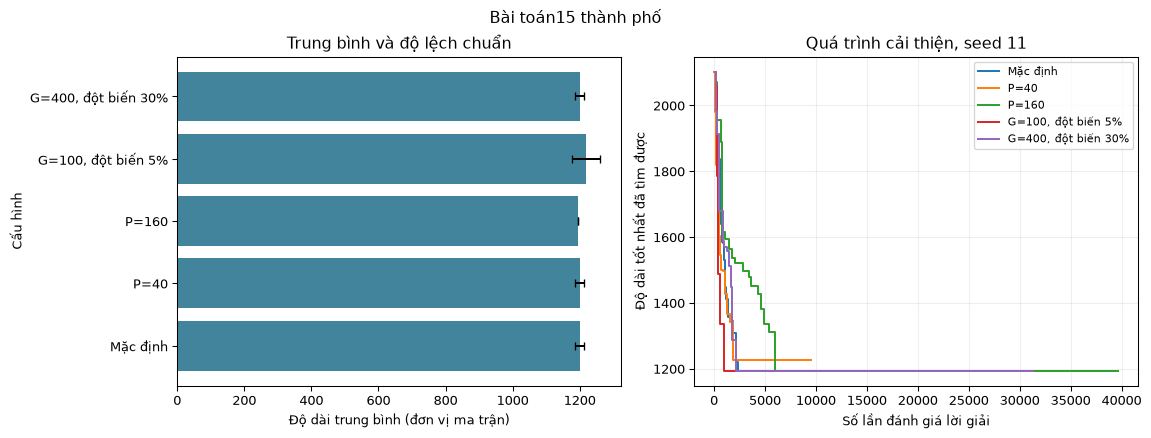

In [5]:
case15 = run_group(problem, configs)
case15_summary = present_group(case15, 'Bài toán15 thành phố')

In [6]:
discuss(case15_summary, 'Một cấu hình tạo tour ngắn hơn có thể đã dùng nhiều phép tính hơn; đây không phải đối chiếu cùng evaluations.')

**Nhận xét từ dữ liệu vừa chạy.** **P=40** có trung bình 1200.20, chênh +0.00 đơn vị so với **Mặc định**; số đánh giá trung bình là 9540 thay vì 19580. **P=160** có trung bình 1194.00, chênh -6.20 đơn vị so với **Mặc định**; số đánh giá trung bình là 39660 thay vì 19580. **G=100, đột biến 5%** có trung bình 1219.20, chênh +19.00 đơn vị so với **Mặc định**; số đánh giá trung bình là 7880 thay vì 19580. **G=400, đột biến 30%** có trung bình 1200.20, chênh +0.00 đơn vị so với **Mặc định**; số đánh giá trung bình là 31280 thay vì 19580.

Trong nhóm này, P=160 có trung bình nhỏ nhất (1194.00). Một cấu hình tạo tour ngắn hơn có thể đã dùng nhiều phép tính hơn; đây không phải đối chiếu cùng evaluations. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

In [7]:
case_summaries[15], all_case_runs[15] = case15_summary, case15

## Trường hợp 2 — Bài toán 26 thành phố

Mang cấu hình P160,400 thế hệ,30%đột biến từ trường hợp 15 sang để kiểm tra khả năng sử dụng lại; cấu hình này được chọn trước khi nhìn kết quả, không tự chọn run đẹp nhất. Sau đó giảm P, giảm tỷ lệ đột biến hoặc đổi chọn lọc sang Rank Selection (chọn theo thứ hạng) và Roulette Wheel Selection (chọn ngẫu nhiên có trọng số ưu tiên tuyến ngắn). Giữ OX/Inversion để không trộn thêm thay đổi phép lai và đột biến.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [8]:
problem = load_matrix(ROOT/'data/26Cities-937.txt')
TRANSFER = replace(DEFAULT, population_size=160, generations=400, max_iterations=400, mutation_rate=.30)
configs = {'Kế thừa P160, G400': TRANSFER, 'Giảm P còn40': replace(TRANSFER, population_size=40),
           'Giảm đột biến còn5%': replace(TRANSFER, mutation_rate=.05),
           'Chọn lọc Rank': replace(TRANSFER, selection_method='rank'),
           'Chọn lọc Roulette': replace(TRANSFER, selection_method='roulette_wheel')}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Kế thừa P160, G400 | 160 | 400/400 | 0.3 | Không đặt thêm |
| Giảm P còn40 | 40 | 400/400 | 0.3 | Không đặt thêm |
| Giảm đột biến còn5% | 160 | 400/400 | 0.05 | Không đặt thêm |
| Chọn lọc Rank | 160 | 400/400 | 0.3 | Không đặt thêm |
| Chọn lọc Roulette | 160 | 400/400 | 0.3 | Không đặt thêm |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Kế thừa P160, G400 | 937 | 966.00 | 25.32 | 63360–63360 | 400.0 | 1.4430 | MAX_ITERATIONS: 5 |
| Giảm P còn40 | 937 | 970.20 | 29.46 | 15240–15240 | 400.0 | 0.3285 | MAX_ITERATIONS: 5 |
| Giảm đột biến còn5% | 937 | 976.80 | 33.74 | 63360–63360 | 400.0 | 1.3789 | MAX_ITERATIONS: 5 |
| Chọn lọc Rank | 1057 | 1150.60 | 56.67 | 63360–63360 | 400.0 | 1.4734 | MAX_ITERATIONS: 5 |
| Chọn lọc Roulette | 1046 | 1119.40 | 80.76 | 63360–63360 | 400.0 | 1.4461 | MAX_ITERATIONS: 5 |

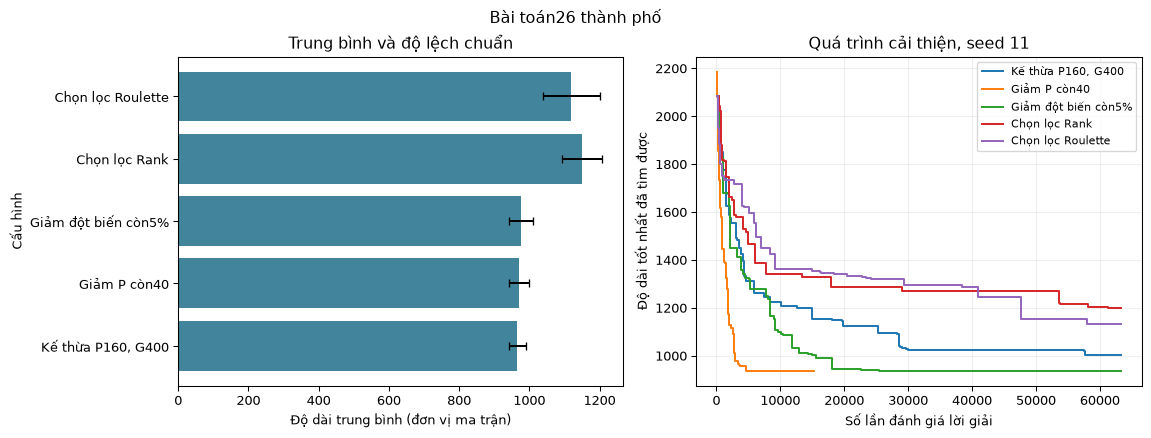

In [9]:
case26 = run_group(problem, configs)
case26_summary = present_group(case26, 'Bài toán26 thành phố')

In [10]:
discuss(case26_summary, 'Không thể mặc định tham số phù hợp15 thành phố sẽ phù hợp26 thành phố; việc đổi ma trận làm thay đổi bài toán tìm kiếm.')

**Nhận xét từ dữ liệu vừa chạy.** **Giảm P còn40** có trung bình 970.20, chênh +4.20 đơn vị so với **Kế thừa P160, G400**; số đánh giá trung bình là 15240 thay vì 63360. **Giảm đột biến còn5%** có trung bình 976.80, chênh +10.80 đơn vị so với **Kế thừa P160, G400**; số đánh giá trung bình là 63360 thay vì 63360. **Chọn lọc Rank** có trung bình 1150.60, chênh +184.60 đơn vị so với **Kế thừa P160, G400**; số đánh giá trung bình là 63360 thay vì 63360. **Chọn lọc Roulette** có trung bình 1119.40, chênh +153.40 đơn vị so với **Kế thừa P160, G400**; số đánh giá trung bình là 63360 thay vì 63360.

Trong nhóm này, Kế thừa P160, G400 có trung bình nhỏ nhất (966.00). Không thể mặc định tham số phù hợp15 thành phố sẽ phù hợp26 thành phố; việc đổi ma trận làm thay đổi bài toán tìm kiếm. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

In [11]:
case_summaries[26], all_case_runs[26] = case26_summary, case26

## Trường hợp 3 — Bài toán 42 thành phố

Quay về mặc định của ứng dụng làm mốc dễ đọc, rồi giảm/tăng thế hệ, thay P, thử Rank/Roulette và PMX. Partially Mapped Crossover (PMX) là phép lai dùng ánh xạ đoạn để giữ tour hợp lệ, khác OX vốn ưu tiên thứ tự. Các cặp cùng P và G như default/Rank/Roulette/PMX mới có cùng số evaluations khi hoàn tất; các cặp tăng P hoặc G cần được đọc cùng số phép tính đã dùng.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [12]:
problem = load_matrix(ROOT/'data/42Cities-699.txt')
configs = {'Mặc định': DEFAULT, 'G=100': replace(DEFAULT, generations=100, max_iterations=100),
           'G=500': replace(DEFAULT, generations=500, max_iterations=500),
           'P=40': replace(DEFAULT, population_size=40), 'P=160': replace(DEFAULT, population_size=160),
           'Rank': replace(DEFAULT, selection_method='rank'),
           'Roulette': replace(DEFAULT, selection_method='roulette_wheel'),
           'PMX': replace(DEFAULT, crossover_method='pmx')}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Mặc định | 80 | 250/250 | 0.15 | Không đặt thêm |
| G=100 | 80 | 100/100 | 0.15 | Không đặt thêm |
| G=500 | 80 | 500/500 | 0.15 | Không đặt thêm |
| P=40 | 40 | 250/250 | 0.15 | Không đặt thêm |
| P=160 | 160 | 250/250 | 0.15 | Không đặt thêm |
| Rank | 80 | 250/250 | 0.15 | Không đặt thêm |
| Roulette | 80 | 250/250 | 0.15 | Không đặt thêm |
| PMX | 80 | 250/250 | 0.15 | Không đặt thêm |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Mặc định | 741 | 781.00 | 23.29 | 19580–19580 | 250.0 | 0.5594 | MAX_ITERATIONS: 5 |
| G=100 | 900 | 1025.00 | 75.87 | 7880–7880 | 100.0 | 0.2374 | MAX_ITERATIONS: 5 |
| G=500 | 714 | 744.80 | 21.06 | 39080–39080 | 500.0 | 1.1784 | MAX_ITERATIONS: 5 |
| P=40 | 838 | 861.60 | 19.83 | 9540–9540 | 250.0 | 0.2778 | MAX_ITERATIONS: 5 |
| P=160 | 734 | 777.80 | 36.07 | 39660–39660 | 250.0 | 1.1834 | MAX_ITERATIONS: 5 |
| Rank | 1144 | 1263.40 | 148.85 | 19580–19580 | 250.0 | 0.4567 | MAX_ITERATIONS: 5 |
| Roulette | 1183 | 1275.20 | 92.59 | 19580–19580 | 250.0 | 0.5157 | MAX_ITERATIONS: 5 |
| PMX | 722 | 785.60 | 36.58 | 19580–19580 | 250.0 | 0.5095 | MAX_ITERATIONS: 5 |

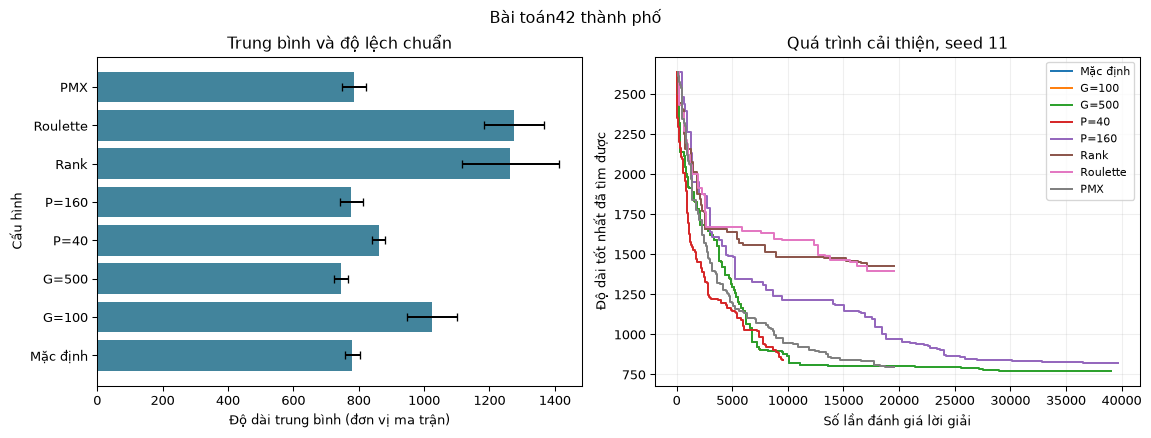

In [13]:
case42 = run_group(problem, configs)
case42_summary = present_group(case42, 'Bài toán42 thành phố')

In [14]:
discuss(case42_summary, 'Đường hội tụ có thể dừng ở evaluations khác nhau. Không nối thêm đường sau khi run đã dừng để tạo cảm giác chúng dùng cùng nguồn lực.')

**Nhận xét từ dữ liệu vừa chạy.** **G=100** có trung bình 1025.00, chênh +244.00 đơn vị so với **Mặc định**; số đánh giá trung bình là 7880 thay vì 19580. **G=500** có trung bình 744.80, chênh -36.20 đơn vị so với **Mặc định**; số đánh giá trung bình là 39080 thay vì 19580. **P=40** có trung bình 861.60, chênh +80.60 đơn vị so với **Mặc định**; số đánh giá trung bình là 9540 thay vì 19580. **P=160** có trung bình 777.80, chênh -3.20 đơn vị so với **Mặc định**; số đánh giá trung bình là 39660 thay vì 19580. **Rank** có trung bình 1263.40, chênh +482.40 đơn vị so với **Mặc định**; số đánh giá trung bình là 19580 thay vì 19580. **Roulette** có trung bình 1275.20, chênh +494.20 đơn vị so với **Mặc định**; số đánh giá trung bình là 19580 thay vì 19580. **PMX** có trung bình 785.60, chênh +4.60 đơn vị so với **Mặc định**; số đánh giá trung bình là 19580 thay vì 19580.

Trong nhóm này, G=500 có trung bình nhỏ nhất (744.80). Đường hội tụ có thể dừng ở evaluations khác nhau. Không nối thêm đường sau khi run đã dừng để tạo cảm giác chúng dùng cùng nguồn lực. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

In [15]:
case_summaries[42], all_case_runs[42] = case42_summary, case42

## Trường hợp 4 — Bài toán 48 thành phố và các chức năng mới

Đây là bài lớn nhất trong 7 ma trận hiện có. Để đọc tác động rõ hơn, tất cả cấu hình dưới dùng P80 và tối đa 6000 evaluations ở QUICK hoặc 12000 ở FULL, hai giới hạn thế hệ 2000. Đổi sang giới hạn lớn hơn trong FULL là một điều kiện mới đã công bố; không so trực tiếp một run QUICK với một run FULL để gán toàn bộ tác động cho seed.

**A. Khởi tạo quần thể.** Random Initialization tạo tour ngẫu nhiên. Nearest Neighbor Initialization chọn tiếp thành phố chưa thăm gần nhất, thử nhiều điểm xuất phát rồi đưa thành phố 0 về đầu. Mixed Initialization kết hợp một phần 25%tour dựng theo cách gần nhất với các tour ngẫu nhiên. Đây là cách khởi tạo hỗ trợ GA, không phải một thuật toán chính mới. Chúng tôi đo cả chất lượng ban đầu và cuối để kiểm tra điểm khởi đầu tốt có chuyển thành kết quả cuối tốt hay không; công việc dựng tour tham lam nằm trong runtime dù không phải full evaluations.

**B. Lai ghép.** So PMX với OX trong cùng điều kiện, không thay mutation khi chỉ đổi phép lai. Cả hai phải giữ hoán vị đủ thành phố.

**C. Adaptive Mutation (đột biến thích nghi).** Tỷ lệ đột biến được điều chỉnh khi nhiều thế hệ không cải thiện hoặc quần thể ít đa dạng. Điều này có thể tăng khả năng tạo biến đổi, nhưng cần đo chứ không mặc định tốt hơn. Phiên bản hiện tại có giới hạn xác suất tối thiểu 0.05, tối đa 0.5 và mốc 20 thế hệ để tăng áp lực theo trì trệ.

**D. 2-opt Local Search (tìm kiếm cục bộ 2-opt).** Thuật toán thử đảo đoạn, tương ứng thay cách nối hai phần của tour, và nhận thay đổi nếu làm tuyến ngắn hơn. Chúng tôi chỉ cho phép một lần cải thiện và tối đa 10 lần thử cho mỗi cá thể con. Mỗi lần thử đều tính lại độ dài toàn bộ tuyến đường và nằm trong tổng evaluations. Run được ghi là **GA+2-opt**, không phải GA thuần. Cùng giới hạn đánh giá, tính toán cục bộ có thể làm giảm số thế hệ GA; vì vậy kết quả cuối có thể kém hơn cấu hình cơ bản.

**E. Kết hợp có chọn lọc.** Thử PMX+Mixed và Mixed+Adaptive để xem hai lựa chọn khởi tạo/lai hoặc khởi tạo/đột biến phối hợp thế nào. Chúng thay đổi nhiều yếu tố nên được tách tên rõ, không dùng để chứng minh tác động riêng của một toán tử. Không thử toàn bộ tổ hợp có thể có.

Các hình ở từng nhóm dùng cùng evaluations trên trục ngang. Nhóm thử dừng do trì trệ ở phía sau được tách riêng vì có thể dùng ít phép đánh giá hơn, không gộp vào đối chiếu cùng lượng tính toán.

In [16]:
problem48 = load_matrix(ROOT/'data/48Cities-33523.txt')
EVALUATIONS48 = 6000 if MODE == 'QUICK' else 12000
BASE48 = replace(DEFAULT, generations=2000, max_iterations=2000,
                 max_evaluations=EVALUATIONS48, time_limit_seconds=10.0)
INIT_CONFIGS = {'Ngẫu nhiên': BASE48,
                'Gần nhất': replace(BASE48, initialization_method='nearest_neighbor'),
                'Kết hợp25%': replace(BASE48, initialization_method='mixed')}
ADVANCED_CONFIGS = {'Ngẫu nhiên + OX': BASE48,
                    'PMX': replace(BASE48, crossover_method='pmx'),
                    'Adaptive': replace(BASE48, adaptive_mutation=True),
                    'GA+2-opt': replace(BASE48, local_search_enabled=True,
                                        local_search_max_moves=1, local_search_max_probes=10),
                    'PMX + Mixed': replace(BASE48, crossover_method='pmx', initialization_method='mixed'),
                    'Mixed + Adaptive': replace(BASE48, initialization_method='mixed', adaptive_mutation=True)}

### A — Chất lượng khởi đầu và kết quả cuối

Chạy đủ ba cách khởi tạo với cùng seed và evaluations. Ngoài hình hội tụ và bảng kết quả cuối, bảng tiếp theo ghi độ dài tốt nhất ngay sau khởi tạo để quan sát điểm xuất phát.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [17]:
configs = INIT_CONFIGS

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Ngẫu nhiên | 80 | 2000/2000 | 0.15 | 6000 |
| Gần nhất | 80 | 2000/2000 | 0.15 | 6000 |
| Kết hợp25% | 80 | 2000/2000 | 0.15 | 6000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Ngẫu nhiên | 47650 | 54194.40 | 3861.50 | 6000–6000 | 75.0 | 0.2053 | MAX_EVALUATIONS: 5 |
| Gần nhất | 35512 | 36087.80 | 413.78 | 6000–6000 | 75.0 | 0.1677 | MAX_EVALUATIONS: 5 |
| Kết hợp25% | 35237 | 36463.20 | 814.01 | 6000–6000 | 75.0 | 0.1535 | MAX_EVALUATIONS: 5 |

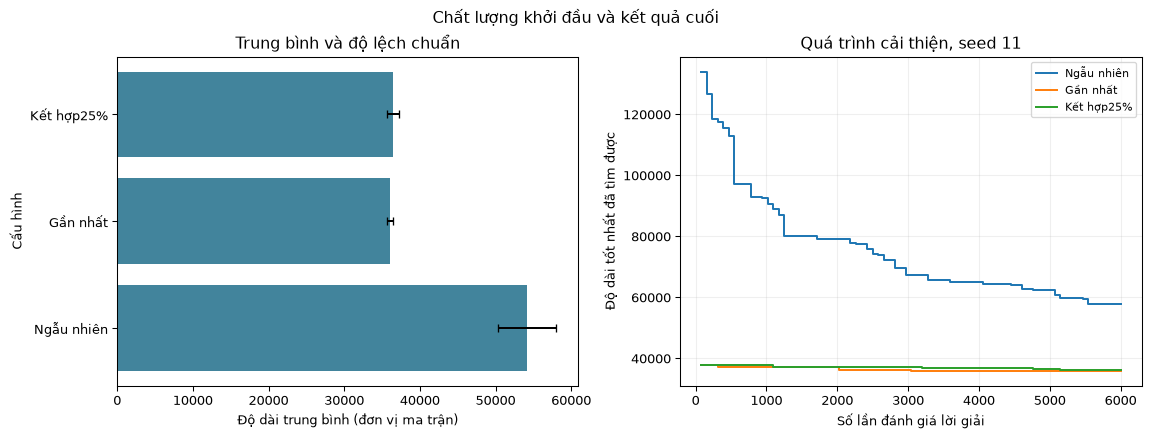

In [18]:
initialization48 = run_group(problem48, configs)
initialization48_summary = present_group(initialization48, 'Chất lượng khởi đầu và kết quả cuối')

In [19]:
discuss(initialization48_summary, 'Mỗi cấu hình đều đánh giá đủ80 tour ban đầu. Khởi tạo gần nhất còn thực hiện thêm tra cứu ma trận; thời gian không được bỏ qua.')

**Nhận xét từ dữ liệu vừa chạy.** **Gần nhất** có trung bình 36087.80, chênh -18106.60 đơn vị so với **Ngẫu nhiên**; số đánh giá trung bình là 6000 thay vì 6000. **Kết hợp25%** có trung bình 36463.20, chênh -17731.20 đơn vị so với **Ngẫu nhiên**; số đánh giá trung bình là 6000 thay vì 6000.

Trong nhóm này, Gần nhất có trung bình nhỏ nhất (36087.80). Mỗi cấu hình đều đánh giá đủ80 tour ban đầu. Khởi tạo gần nhất còn thực hiện thêm tra cứu ma trận; thời gian không được bỏ qua. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

In [20]:
show_table(['Khởi tạo', 'Best ban đầu TB', 'Best cuối TB', 'Mức giảm TB'],
           [[name, f"{s['initial_mean']:.2f}", f"{s['mean']:.2f}", f"{s['initial_mean'] - s['mean']:.2f}"]
            for name, s in initialization48_summary.items()])
initial_order = ', '.join(f"{name}: {s['initial_mean']:.2f} → {s['mean']:.2f}" for name,s in initialization48_summary.items())
display(Markdown('**Nhận xét về khởi tạo.** Độ dài trung bình tốt nhất ban đầu và cuối lần lượt là ' + initial_order + '. '
    'Bảng cho phép kiểm tra liệu lợi thế ban đầu còn được duy trì tới cuối, thay vì chỉ nhìn tour ở thời điểm khởi tạo. '
    'Kết quả phụ thuộc ma trận và số phép đánh giá; không kết luận khởi tạo có định hướng luôn thắng.'))

| Khởi tạo | Best ban đầu TB | Best cuối TB | Mức giảm TB |
| --- | --- | --- | --- |
| Ngẫu nhiên | 132770.00 | 54194.40 | 78575.60 |
| Gần nhất | 37928.00 | 36087.80 | 1840.20 |
| Kết hợp25% | 38205.60 | 36463.20 | 1742.40 |

**Nhận xét về khởi tạo.** Độ dài trung bình tốt nhất ban đầu và cuối lần lượt là Ngẫu nhiên: 132770.00 → 54194.40, Gần nhất: 37928.00 → 36087.80, Kết hợp25%: 38205.60 → 36463.20. Bảng cho phép kiểm tra liệu lợi thế ban đầu còn được duy trì tới cuối, thay vì chỉ nhìn tour ở thời điểm khởi tạo. Kết quả phụ thuộc ma trận và số phép đánh giá; không kết luận khởi tạo có định hướng luôn thắng.

### B–E — Lai ghép, đột biến thích nghi và tìm kiếm cục bộ

Các mức giới hạn của 2-opt được giữ nhỏ để số lần thử hữu hạn. Chúng tôi giữ cả trường hợp 2-opt kém hơn GA cơ bản; bảng sau hình còn chỉ rõ bao nhiêu evaluations dành cho tìm kiếm cục bộ.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [21]:
configs = ADVANCED_CONFIGS

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Ngẫu nhiên + OX | 80 | 2000/2000 | 0.15 | 6000 |
| PMX | 80 | 2000/2000 | 0.15 | 6000 |
| Adaptive | 80 | 2000/2000 | 0.15 | 6000 |
| GA+2-opt | 80 | 2000/2000 | 0.15 | 6000 |
| PMX + Mixed | 80 | 2000/2000 | 0.15 | 6000 |
| Mixed + Adaptive | 80 | 2000/2000 | 0.15 | 6000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Ngẫu nhiên + OX | 47650 | 54194.40 | 3861.50 | 6000–6000 | 75.0 | 0.1584 | MAX_EVALUATIONS: 5 |
| PMX | 50218 | 53609.00 | 3655.49 | 6000–6000 | 75.0 | 0.1412 | MAX_EVALUATIONS: 5 |
| Adaptive | 47414 | 54129.20 | 4122.54 | 6000–6000 | 75.0 | 0.1543 | MAX_EVALUATIONS: 5 |
| GA+2-opt | 79054 | 82686.40 | 2832.55 | 6000–6000 | 15.6 | 0.1198 | MAX_EVALUATIONS: 5 |
| PMX + Mixed | 35910 | 36323.60 | 425.11 | 6000–6000 | 75.0 | 0.1808 | MAX_EVALUATIONS: 5 |
| Mixed + Adaptive | 35652 | 35964.40 | 290.12 | 6000–6000 | 75.0 | 0.1866 | MAX_EVALUATIONS: 5 |

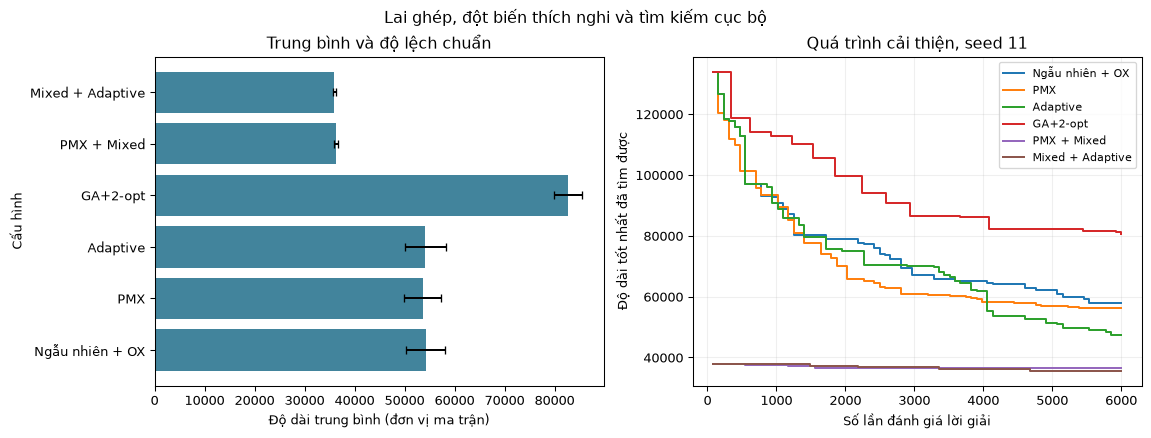

In [22]:
advanced48 = run_group(problem48, configs)
advanced48_summary = present_group(advanced48, 'Lai ghép, đột biến thích nghi và tìm kiếm cục bộ')

In [23]:
discuss(advanced48_summary, 'Các biến thể một yếu tố và hai yếu tố đã được đặt tên riêng; cần đọc số thế hệ và chi phí cục bộ trước khi quy lợi ích cho một thành phần.')

**Nhận xét từ dữ liệu vừa chạy.** **PMX** có trung bình 53609.00, chênh -585.40 đơn vị so với **Ngẫu nhiên + OX**; số đánh giá trung bình là 6000 thay vì 6000. **Adaptive** có trung bình 54129.20, chênh -65.20 đơn vị so với **Ngẫu nhiên + OX**; số đánh giá trung bình là 6000 thay vì 6000. **GA+2-opt** có trung bình 82686.40, chênh +28492.00 đơn vị so với **Ngẫu nhiên + OX**; số đánh giá trung bình là 6000 thay vì 6000. **PMX + Mixed** có trung bình 36323.60, chênh -17870.80 đơn vị so với **Ngẫu nhiên + OX**; số đánh giá trung bình là 6000 thay vì 6000. **Mixed + Adaptive** có trung bình 35964.40, chênh -18230.00 đơn vị so với **Ngẫu nhiên + OX**; số đánh giá trung bình là 6000 thay vì 6000.

Trong nhóm này, Mixed + Adaptive có trung bình nhỏ nhất (35964.40). Các biến thể một yếu tố và hai yếu tố đã được đặt tên riêng; cần đọc số thế hệ và chi phí cục bộ trước khi quy lợi ích cho một thành phần. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

In [24]:
show_table(['Cấu hình', 'Tổng đánh giá TB', 'Đánh giá cục bộ TB', 'Thế hệ hoàn tất TB'],
           [[name, f"{s['eval_mean']:.0f}", f"{s['local_calls']:.1f}", f"{s['generations']:.1f}"]
            for name,s in advanced48_summary.items()])
local = advanced48_summary['GA+2-opt']
basic = advanced48_summary['Ngẫu nhiên + OX']
delta = local['mean'] - basic['mean']
quality_word = 'dài hơn' if delta > 0 else 'ngắn hơn' if delta < 0 else 'bằng'
display(Markdown(f'**Nhận xét riêng về 2-opt.** Trong mẫu này, độ dài trung bình của GA+2-opt là '
    f"{local['mean']:.2f}, {quality_word} cấu hình GA cơ bản ({basic['mean']:.2f}), chênh {delta:+.2f} đơn vị. "
    f"Mỗi run dùng trung bình {local['local_calls']:.1f}/{local['eval_mean']:.0f} lần đánh giá cho các phép thử cục bộ, "
    f"và hoàn tất {local['generations']:.1f} thế hệ, so với {basic['generations']:.1f} ở GA cơ bản. "
    'Việc chia phép tính cho tìm kiếm cục bộ làm thay đổi số con và số thế hệ có thể khảo sát. '
    'Đây là một cách giải thích cần đọc cùng số liệu, không phải bằng chứng2-opt luôn có lợi hoặc luôn bất lợi.'))

| Cấu hình | Tổng đánh giá TB | Đánh giá cục bộ TB | Thế hệ hoàn tất TB |
| --- | --- | --- | --- |
| Ngẫu nhiên + OX | 6000 | 0.0 | 75.0 |
| PMX | 6000 | 0.0 | 75.0 |
| Adaptive | 6000 | 0.0 | 75.0 |
| GA+2-opt | 6000 | 4658.8 | 15.6 |
| PMX + Mixed | 6000 | 0.0 | 75.0 |
| Mixed + Adaptive | 6000 | 0.0 | 75.0 |

**Nhận xét riêng về 2-opt.** Trong mẫu này, độ dài trung bình của GA+2-opt là 82686.40, dài hơn cấu hình GA cơ bản (54194.40), chênh +28492.00 đơn vị. Mỗi run dùng trung bình 4658.8/6000 lần đánh giá cho các phép thử cục bộ, và hoàn tất 15.6 thế hệ, so với 75.0 ở GA cơ bản. Việc chia phép tính cho tìm kiếm cục bộ làm thay đổi số con và số thế hệ có thể khảo sát. Đây là một cách giải thích cần đọc cùng số liệu, không phải bằng chứng2-opt luôn có lợi hoặc luôn bất lợi.

### F — Dừng khi nhiều thế hệ không cải thiện

Stagnation là hiện tượng nhiều thế hệ liên tiếp không cải thiện best toàn lịch sử. Thử dừng sau 20 thế hệ như vậy bằng stagnation_patience. Mẫu này có thể dừng trước khi dùng hết evaluations, nên được tách khỏi phần so sánh cùng phép tính ở trên. Tham số chỉ là điều kiện dừng, không bảo đảm lời giải tối ưu.


Đọc biểu đồ cột để so độ dài trung bình và độ lệch chuẩn của các cấu hình trong nhóm này. Các đường bên phải minh họa quá trình cải thiện ở seed đầu đã công bố; dùng cột evaluations và lý do dừng trong bảng để kiểm tra lượng tính toán thực tế.

In [25]:
configs = {'Không dừng vì trì trệ': BASE48,
           'Dừng sau20 thế hệ': replace(BASE48, stagnation_patience=20)}

| Cấu hình | Quần thể P | Thế hệ G/M | Tỷ lệ đột biến | Giới hạn đánh giá |
| --- | --- | --- | --- | --- |
| Không dừng vì trì trệ | 80 | 2000/2000 | 0.15 | 6000 |
| Dừng sau20 thế hệ | 80 | 2000/2000 | 0.15 | 6000 |

| Cấu hình | Tốt nhất | Trung bình | Độ lệch chuẩn | Đánh giá min–max | Thế hệ TB | Thời gian TB (s) | Lý do dừng (số lần) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Không dừng vì trì trệ | 47650 | 54194.40 | 3861.50 | 6000–6000 | 75.0 | 0.1738 | MAX_EVALUATIONS: 5 |
| Dừng sau20 thế hệ | 47650 | 54194.40 | 3861.50 | 6000–6000 | 75.0 | 0.1946 | MAX_EVALUATIONS: 5 |

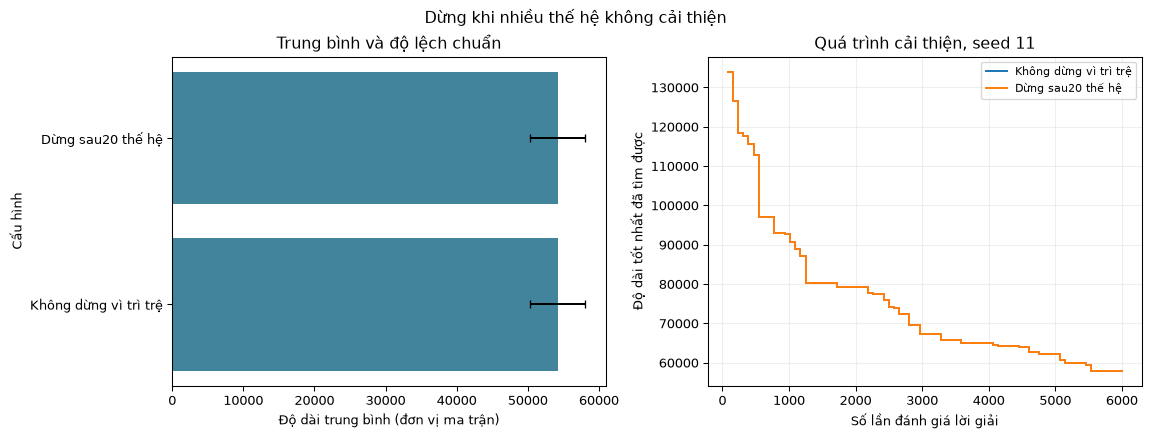

In [26]:
stagnation48 = run_group(problem48, configs)
stagnation48_summary = present_group(stagnation48, 'Dừng khi nhiều thế hệ không cải thiện')

In [27]:
discuss(stagnation48_summary, 'Nếu lý do làSTAGNATION, độ dài không cải thiện trong20 vòng hoàn tất; không có nghĩa không còn tour tốt hơn trong không gian tìm kiếm.')

**Nhận xét từ dữ liệu vừa chạy.** **Dừng sau20 thế hệ** có trung bình 54194.40, chênh +0.00 đơn vị so với **Không dừng vì trì trệ**; số đánh giá trung bình là 6000 thay vì 6000.

Trong nhóm này, Không dừng vì trì trệ, Dừng sau20 thế hệ có trung bình nhỏ nhất (54194.40). Nếu lý do làSTAGNATION, độ dài không cải thiện trong20 vòng hoàn tất; không có nghĩa không còn tour tốt hơn trong không gian tìm kiếm. Kết luận chỉ áp dụng cho dữ liệu, tham số và 5 seed đã công bố; chưa đủ để khẳng định cấu hình đó tốt nhất cho mọi bài toán TSP.

In [28]:
case_summaries[48] = {**initialization48_summary,
                      **{k:v for k,v in advanced48_summary.items() if k != 'Ngẫu nhiên + OX'},
                      'Dừng vì trì trệ': stagnation48_summary['Dừng sau20 thế hệ']}
all_case_runs[48] = {**initialization48, **advanced48, **stagnation48}

## Tổng hợp Experiment 4

Bảng tổng hợp dưới giữ tên cấu hình trong từng trường hợp để đọc lại điều kiện đã thay đổi. Độ dài trung bình và tốt nhất cho biết chất lượng trong mẫu, còn evaluations và thời gian cho biết lượng tính toán thực đã dùng. Chỉ các dòng thuộc phép đối chiếu cùng evaluations ở48 thành phố mới có thể đọc như dùng cùng lượng lần tính độ dài toàn bộ tuyến đường; nhóm dừng vì trì trệ được ghi riêng. Không lấy số trong tên file làm optimum cho bất kỳ bài lớn nào.

In [29]:
show_table(['Thành phố', 'Cấu hình', 'Độ dài TB', 'Tốt nhất', 'Đánh giá TB', 'Thời gian TB (s)'],
           [[n, name, f"{s['mean']:.2f}", f"{s['best']:g}", f"{s['eval_mean']:.0f}", f"{s['seconds']:.4f}"]
            for n, variants in case_summaries.items() for name, s in variants.items()])
paragraphs = []
for n, variants in case_summaries.items():
    smallest = min(s['mean'] for s in variants.values())
    winners = ', '.join(name for name,s in variants.items() if s['mean'] == smallest)
    paragraphs.append(f'Ở bài {n} thành phố, {winners} có độ dài trung bình nhỏ nhất trong các cấu hình đã thử ({smallest:.2f}).')
display(Markdown('**Kết luận từ bốn trường hợp.** ' + ' '.join(paragraphs) + '\n\n'
    'Các lần điều chỉnh cho thấy chất lượng cần được đọc cùng số cá thể, số thế hệ, evaluations và thời gian thực. '
    'Một cấu hình có kết quả ngắn hơn nhưng dùng nhiều phép tính hơn chưa chứng minh sử dụng nguồn lực tốt hơn. '
    'Khởi tạo gần nhất, PMX và đột biến thích nghi được xem là lựa chọn cần kiểm chứng trên từng ma trận; '
    '2-opt được giữ nhãn biến thể và mọi kết quả bất lợi vẫn có mặt trong bảng. '
    f'Mẫu gồm {len(SEEDS)} seed cho mỗi cấu hình, chưa có kiểm định rộng hoặc optimum đã xác minh cho các bài lớn. '
    'Không tự đổi default GA của ứng dụng từ các quan sát này và không kết luận mọi nâng cấp đều có hiệu quả.'))
repro_problem, repro_result = problem48, advanced48['GA+2-opt'][0]

| Thành phố | Cấu hình | Độ dài TB | Tốt nhất | Đánh giá TB | Thời gian TB (s) |
| --- | --- | --- | --- | --- | --- |
| 15 | Mặc định | 1200.20 | 1194 | 19580 | 0.2559 |
| 15 | P=40 | 1200.20 | 1194 | 9540 | 0.1633 |
| 15 | P=160 | 1194.00 | 1194 | 39660 | 0.7334 |
| 15 | G=100, đột biến 5% | 1219.20 | 1194 | 7880 | 0.1351 |
| 15 | G=400, đột biến 30% | 1200.20 | 1194 | 31280 | 0.6221 |
| 26 | Kế thừa P160, G400 | 966.00 | 937 | 63360 | 1.4430 |
| 26 | Giảm P còn40 | 970.20 | 937 | 15240 | 0.3285 |
| 26 | Giảm đột biến còn5% | 976.80 | 937 | 63360 | 1.3789 |
| 26 | Chọn lọc Rank | 1150.60 | 1057 | 63360 | 1.4734 |
| 26 | Chọn lọc Roulette | 1119.40 | 1046 | 63360 | 1.4461 |
| 42 | Mặc định | 781.00 | 741 | 19580 | 0.5594 |
| 42 | G=100 | 1025.00 | 900 | 7880 | 0.2374 |
| 42 | G=500 | 744.80 | 714 | 39080 | 1.1784 |
| 42 | P=40 | 861.60 | 838 | 9540 | 0.2778 |
| 42 | P=160 | 777.80 | 734 | 39660 | 1.1834 |
| 42 | Rank | 1263.40 | 1144 | 19580 | 0.4567 |
| 42 | Roulette | 1275.20 | 1183 | 19580 | 0.5157 |
| 42 | PMX | 785.60 | 722 | 19580 | 0.5095 |
| 48 | Ngẫu nhiên | 54194.40 | 47650 | 6000 | 0.2053 |
| 48 | Gần nhất | 36087.80 | 35512 | 6000 | 0.1677 |
| 48 | Kết hợp25% | 36463.20 | 35237 | 6000 | 0.1535 |
| 48 | PMX | 53609.00 | 50218 | 6000 | 0.1412 |
| 48 | Adaptive | 54129.20 | 47414 | 6000 | 0.1543 |
| 48 | GA+2-opt | 82686.40 | 79054 | 6000 | 0.1198 |
| 48 | PMX + Mixed | 36323.60 | 35910 | 6000 | 0.1808 |
| 48 | Mixed + Adaptive | 35964.40 | 35652 | 6000 | 0.1866 |
| 48 | Dừng vì trì trệ | 54194.40 | 47650 | 6000 | 0.1946 |

**Kết luận từ bốn trường hợp.** Ở bài 15 thành phố, P=160 có độ dài trung bình nhỏ nhất trong các cấu hình đã thử (1194.00). Ở bài 26 thành phố, Kế thừa P160, G400 có độ dài trung bình nhỏ nhất trong các cấu hình đã thử (966.00). Ở bài 42 thành phố, G=500 có độ dài trung bình nhỏ nhất trong các cấu hình đã thử (744.80). Ở bài 48 thành phố, Mixed + Adaptive có độ dài trung bình nhỏ nhất trong các cấu hình đã thử (35964.40).

Các lần điều chỉnh cho thấy chất lượng cần được đọc cùng số cá thể, số thế hệ, evaluations và thời gian thực. Một cấu hình có kết quả ngắn hơn nhưng dùng nhiều phép tính hơn chưa chứng minh sử dụng nguồn lực tốt hơn. Khởi tạo gần nhất, PMX và đột biến thích nghi được xem là lựa chọn cần kiểm chứng trên từng ma trận; 2-opt được giữ nhãn biến thể và mọi kết quả bất lợi vẫn có mặt trong bảng. Mẫu gồm 5 seed cho mỗi cấu hình, chưa có kiểm định rộng hoặc optimum đã xác minh cho các bài lớn. Không tự đổi default GA của ứng dụng từ các quan sát này và không kết luận mọi nâng cấp đều có hiệu quả.

## Kiểm tra tái lập và tổng kết lần chạy

Chúng tôi chạy lại đúng cấu hình và seed của một kết quả đã có. Tour, độ dài, số lần đánh giá và toàn bộ lịch sử số phải khớp; thời gian được loại khỏi phép so sánh vì phụ thuộc môi trường. Lần kiểm tra này được đếm riêng, không đưa thêm vào thống kê nhiều seed.

In [30]:
repeat = checked_solve(repro_problem, GAConfig(**repro_result.config_snapshot))
assert numeric_signature(repeat) == numeric_signature(repro_result)
expected_main_runs = 29 * len(SEEDS)
assert RUN_COUNT == expected_main_runs + 1
NOTEBOOK_REPORT = dict(notebook='Experiment 4', mode=MODE, seeds=SEEDS,
                       experiment_runs=expected_main_runs, verification_runs=1,
                       total_runs=RUN_COUNT, solver_seconds=SOLVER_SECONDS,
                       wall_seconds=perf_counter() - SESSION_START,
                       summaries=case_summaries)
display(Markdown(f"Đã hoàn tất **{expected_main_runs} lần thực nghiệm** và **1 lần kiểm tra tái lập**, "
    f"tổng {RUN_COUNT} lần gọi GA. Thời gian trong solver là {SOLVER_SECONDS:.3f} giây. "
    'Mọi tour đã qua kiểm tra chi phí và hoán vị; không có lần lỗi nào bị bỏ khỏi thống kê. '
    'Các kết quả khi dừng sớm vẫn được giữ cùng lý do dừng trong bảng.'))

Đã hoàn tất **145 lần thực nghiệm** và **1 lần kiểm tra tái lập**, tổng 146 lần gọi GA. Thời gian trong solver là 73.790 giây. Mọi tour đã qua kiểm tra chi phí và hoán vị; không có lần lỗi nào bị bỏ khỏi thống kê. Các kết quả khi dừng sớm vẫn được giữ cùng lý do dừng trong bảng.